# Data preprocessing-Tree Dataset of Urban Street Classification
https://www.kaggle.com/datasets/erickendric/tree-dataset-of-urban-street-classification-tree


## Objective:
The preprocessing stage was designed to determine whether the image dataset required cleaning, formatting or augumentation before model training. The analysis inspected the dataset structure, class distribution, image formats and dimensions, orientation, image integrity, duplicate images and class imbalance. The original image files were keep unchanged, while model-specific preprocessing was implemented dynamically with torchvision

In [21]:
%pip install pandas

  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.6 MB 5.3 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.6 MB 5.2 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.6 MB 5.0 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.6 MB 4.8 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.6 MB 4.6 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.6 MB 4.5 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.6 MB 4.4 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.6 MB 4.1 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.6 MB 3.9 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.6 MB 3.7 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.6 MB 3.7 MB/s eta 0:00:01
   ------------------------

In [24]:
from pathlib import Path
from collections import Counter, defaultdict
import random
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as display
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

In [5]:

dataset_path = Path("D:\\NEUTRAL_TOMMI\\GROUPPROJECT\\tree")
print(dataset_path)
for file in dataset_path.iterdir():
    if file.is_file():
        print(file.name)
for path in sorted(dataset_path.rglob("*")):
    if path.is_dir():
        level = len(path.relative_to(dataset_path).parts) - 1
        indent = " " * 4 * level
        print(f"{indent}{path.name}/")
        

D:\NEUTRAL_TOMMI\GROUPPROJECT\tree
test/
    Acer palmatum/
    Cedrus deodara/
    Celtis sinensis/
    Cinnamomum camphora (Linn) Presl/
    Elaeocarpus decipiens/
    Flowering cherry/
    Ginkgo biloba/
    Koelreuteria paniculata/
    Lagerstroemia indica/
    Liquidambar formosana/
    Liriodendron chinense/
    Magnolia grandiflora L/
    Magnolia liliflora Desr/
    Michelia chapensis/
    Osmanthus fragrans/
    Photinia serratifolia/
    Platanus/
    Prunus cerasifera f. atropurpurea/
    Salix babylonica/
    Sapindus saponaria/
    Styphnolobium japonicum/
    Triadica sebifera/
    Zelkova serrata/
train/
    Acer palmatum/
    Cedrus deodara/
    Celtis sinensis/
    Cinnamomum camphora (Linn) Presl/
    Elaeocarpus decipiens/
    Flowering cherry/
    Ginkgo biloba/
    Koelreuteria paniculata/
    Lagerstroemia indica/
    Liquidambar formosana/
    Liriodendron chinense/
    Magnolia grandiflora L/
    Magnolia liliflora Desr/
    Michelia chapensis/
    Osmanthus fra

Count images in each folder

Total number of images in training set: 3850
Total number of images in validation set: 482
Total number of images in test set: 472


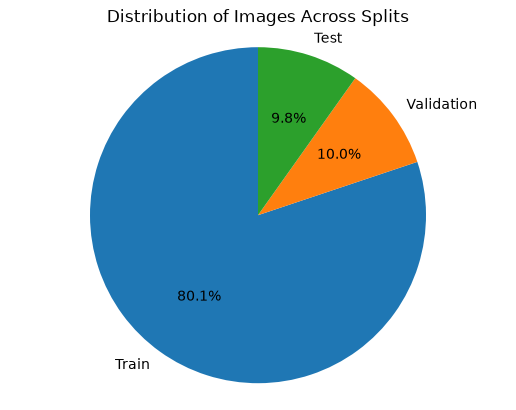

In [67]:
class_counts = {}
for split in ["train", "val", "test"]:
    split_path = dataset_path / split
    class_counts[split] = {}
    for class_folder in split_path.iterdir():
        if class_folder.is_dir():
            class_name = class_folder.name
            image_count = sum(1 for file in class_folder.rglob("*")
            if file.is_file() and file.suffix.lower() in [".jpg", ".jpeg", ".png", ".gif", ".bmp", ".tiff", ".webp"])

            class_counts[split][class_name] = image_count
class_counts

print("Total number of images in training set:", sum(class_counts['train'].values()))
print("Total number of images in validation set:", sum(class_counts['val'].values()))
print("Total number of images in test set:", sum(class_counts['test'].values()))

sizes = [sum(class_counts[split].values()) for split in ["train", "val", "test"]]
labels = ["Train", "Validation", "Test"]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.axis('equal')
plt.title('Distribution of Images Across Splits')
plt.show()


Count classes/species images in each splits

In [46]:

image_extensions = [".jpg", ".jpeg", ".png", ".gif", ".bmp", ".tiff", ".webp"]

def get_image_counts_by_class(split_path):

    image_paths = []
    class_counts = Counter()

    for class_path in split_path.iterdir():
        if class_path.is_dir():
            class_name = class_path.name

            for image_file in class_path.rglob("*"):
                if (
                    image_file.is_file() 
                    and image_file.suffix.lower() in image_extensions
                    ):
                        image_paths.append(image_file)
                        class_counts[class_name] += 1

    return image_paths, class_counts

train_images, train_counts = get_image_counts_by_class(dataset_path / "train")
val_images, val_counts = get_image_counts_by_class(dataset_path / "val")
test_images, test_counts = get_image_counts_by_class(dataset_path / "test")

for split, images, counts in [
    ("train", train_images, train_counts), 
    ("val", val_images, val_counts), 
    ("test", test_images, test_counts)
    ]:

    print(f"\n{'='* 50}")
    print(f"{split.capitalize()} set:")
    print(f"{'=' *50}")

    print(f"Total images: {len(images)}")
    print(f"Number of classes: {len(counts)}")

    print("Class distribution:")
    for class_name in sorted(counts.keys()):
        print(f"  {class_name}: {counts[class_name]} images")
            


Train set:
Total images: 3850
Number of classes: 23
Class distribution:
  Acer palmatum: 162 images
  Cedrus deodara: 125 images
  Celtis sinensis: 188 images
  Cinnamomum camphora (Linn) Presl: 234 images
  Elaeocarpus decipiens: 172 images
  Flowering cherry: 106 images
  Ginkgo biloba: 228 images
  Koelreuteria paniculata: 223 images
  Lagerstroemia indica: 65 images
  Liquidambar formosana: 168 images
  Liriodendron chinense: 182 images
  Magnolia grandiflora L: 212 images
  Magnolia liliflora Desr: 190 images
  Michelia chapensis: 154 images
  Osmanthus fragrans: 173 images
  Photinia serratifolia: 120 images
  Platanus: 193 images
  Prunus cerasifera f. atropurpurea: 99 images
  Salix babylonica: 136 images
  Sapindus saponaria: 224 images
  Styphnolobium japonicum: 157 images
  Triadica sebifera: 154 images
  Zelkova serrata: 185 images

Val set:
Total images: 482
Number of classes: 23
Class distribution:
  Acer palmatum: 21 images
  Cedrus deodara: 16 images
  Celtis sinensis:

Visualize classes between splits

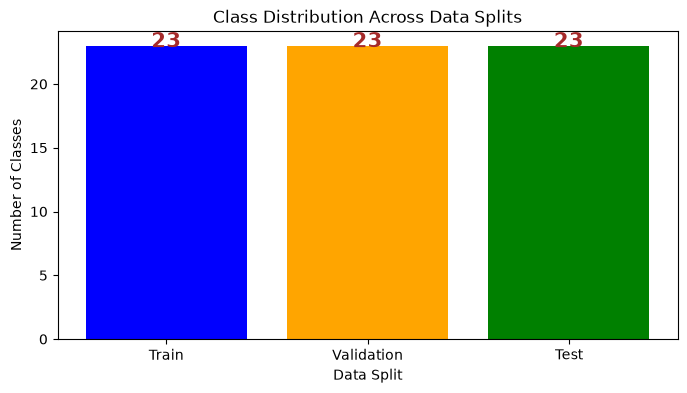

In [60]:
splits = ["Train", "Validation", "Test"]
num_classes = [len(train_counts), len(val_counts), len(test_counts)]
plt.figure(figsize=(8, 4))
bars = plt.bar(splits, num_classes, color=['blue', 'orange', 'green'])
plt.xlabel('Data Split')
plt.ylabel('Number of Classes')
plt.title('Class Distribution Across Data Splits')
plt.xticks(splits)

for bar, value in zip(bars, num_classes):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 0.5, str(value), ha='center', va='bottom', color='brown', fontsize=15, fontweight='bold')    



Identify missing classes between splits

In [58]:
train_class = {
    folder.name for folder in (dataset_path / "train").iterdir() if folder.is_dir()
}

val_class = {
    folder.name for folder in (dataset_path / "val").iterdir() if folder.is_dir()
}

test_class = {
    folder.name for folder in (dataset_path / "test").iterdir() if folder.is_dir()
}

print("Train classes:", len(train_class))
print("Validation classes:", len(val_class))
print("Test classes:", len(test_class))

print("\nClasses missing from validation set:", sorted(train_class - val_class))
print("Classes missing from test set:", sorted(train_class - test_class))
print("Classes missing from training set:", sorted(val_class - train_class))

Train classes: 23
Validation classes: 23
Test classes: 23

Classes missing from validation set: []
Classes missing from test set: []
Classes missing from training set: []


Visualize classes distribution between splits

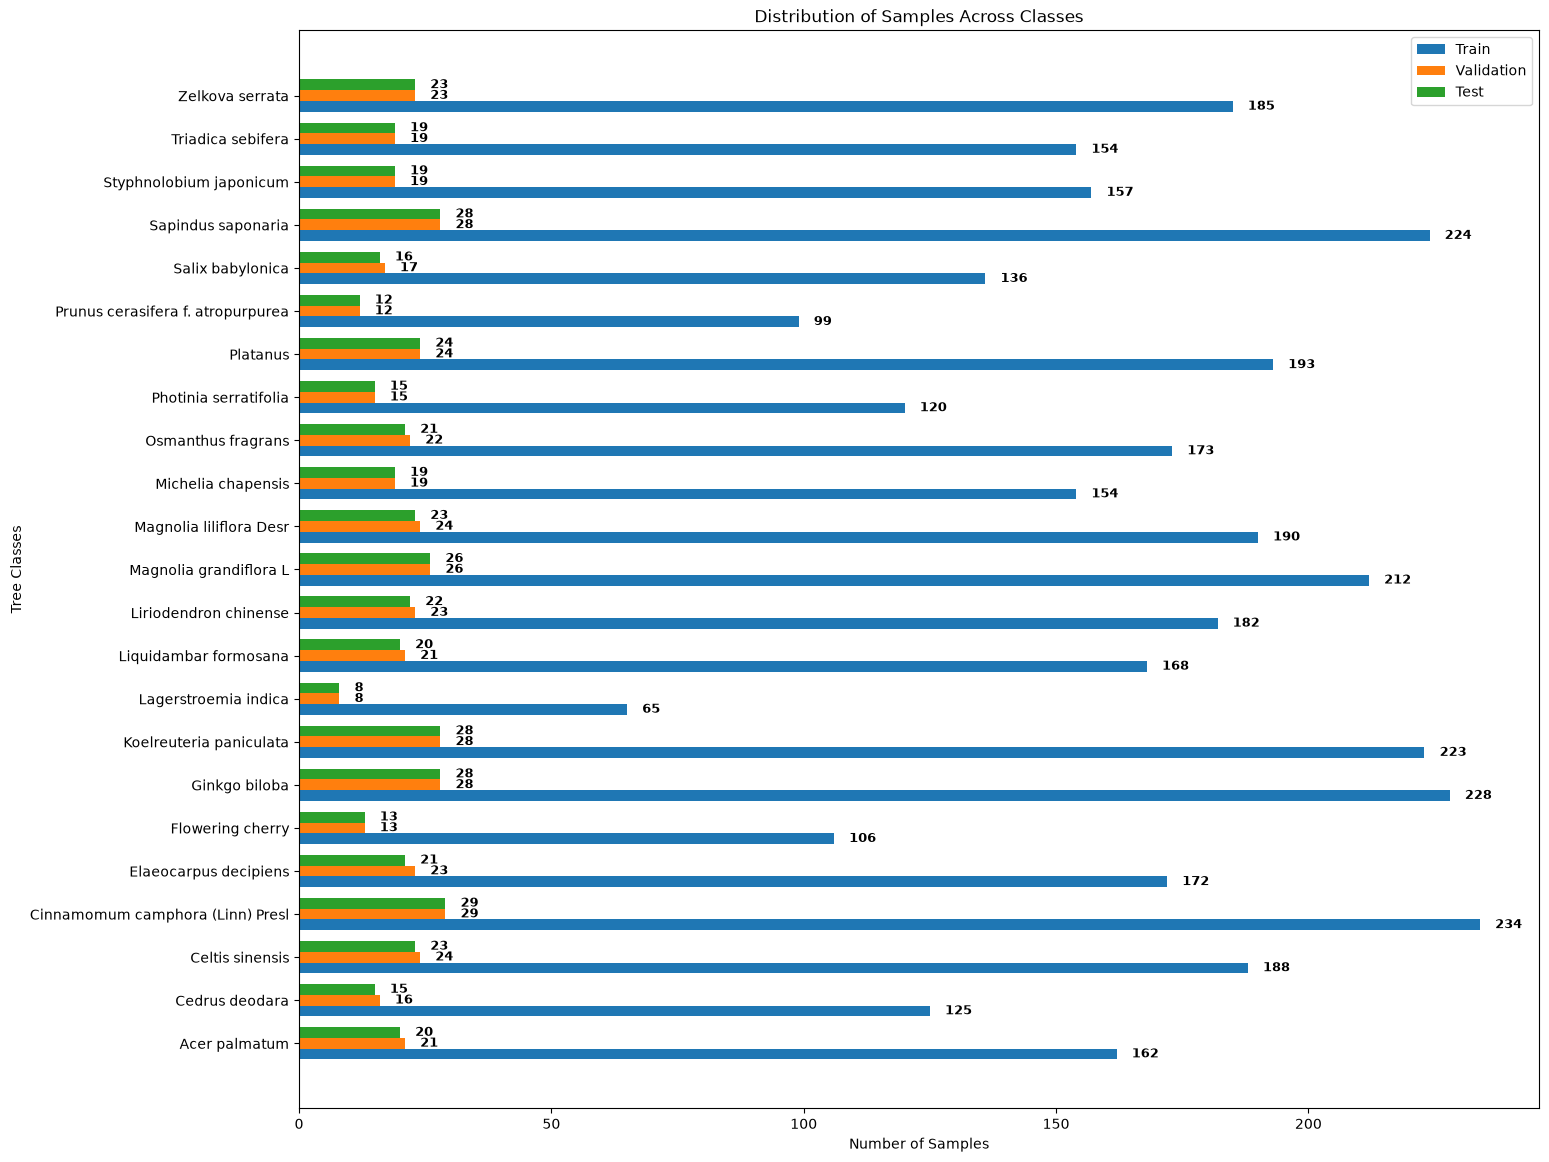

In [47]:
import numpy as np
all_classes = sorted(
    set(train_counts.keys()) | 
    set(val_counts.keys()) | 
    set(test_counts.keys()))

train_values = [train_counts.get(cls, 0) for cls in all_classes]
val_values = [val_counts.get(cls, 0) for cls in all_classes]
test_values = [test_counts.get(cls, 0) for cls in all_classes]

y_pos = np.arange(len(all_classes))
height = 0.25

plt.figure(figsize=(16, 14))

bars_train = plt.barh(y_pos - height, train_values, height, label='Train')
bars_val = plt.barh(y_pos, val_values, height, label='Validation')
bars_test = plt.barh(y_pos + height, test_values, height, label='Test')

for bars in [bars_train, bars_val, bars_test]:
    for bar in bars:
        value = bar.get_width()

        plt.text(value + 3, bar.get_y() + bar.get_height()/2, str(int(value)), va='center', fontsize=9, color='black', fontweight='bold')

plt.yticks(y_pos, all_classes)
plt.xlabel('Number of Samples')
plt.ylabel('Tree Classes')
plt.title('Distribution of Samples Across Classes')
plt.legend()
plt.show()



Display random specie from each class within train dataset

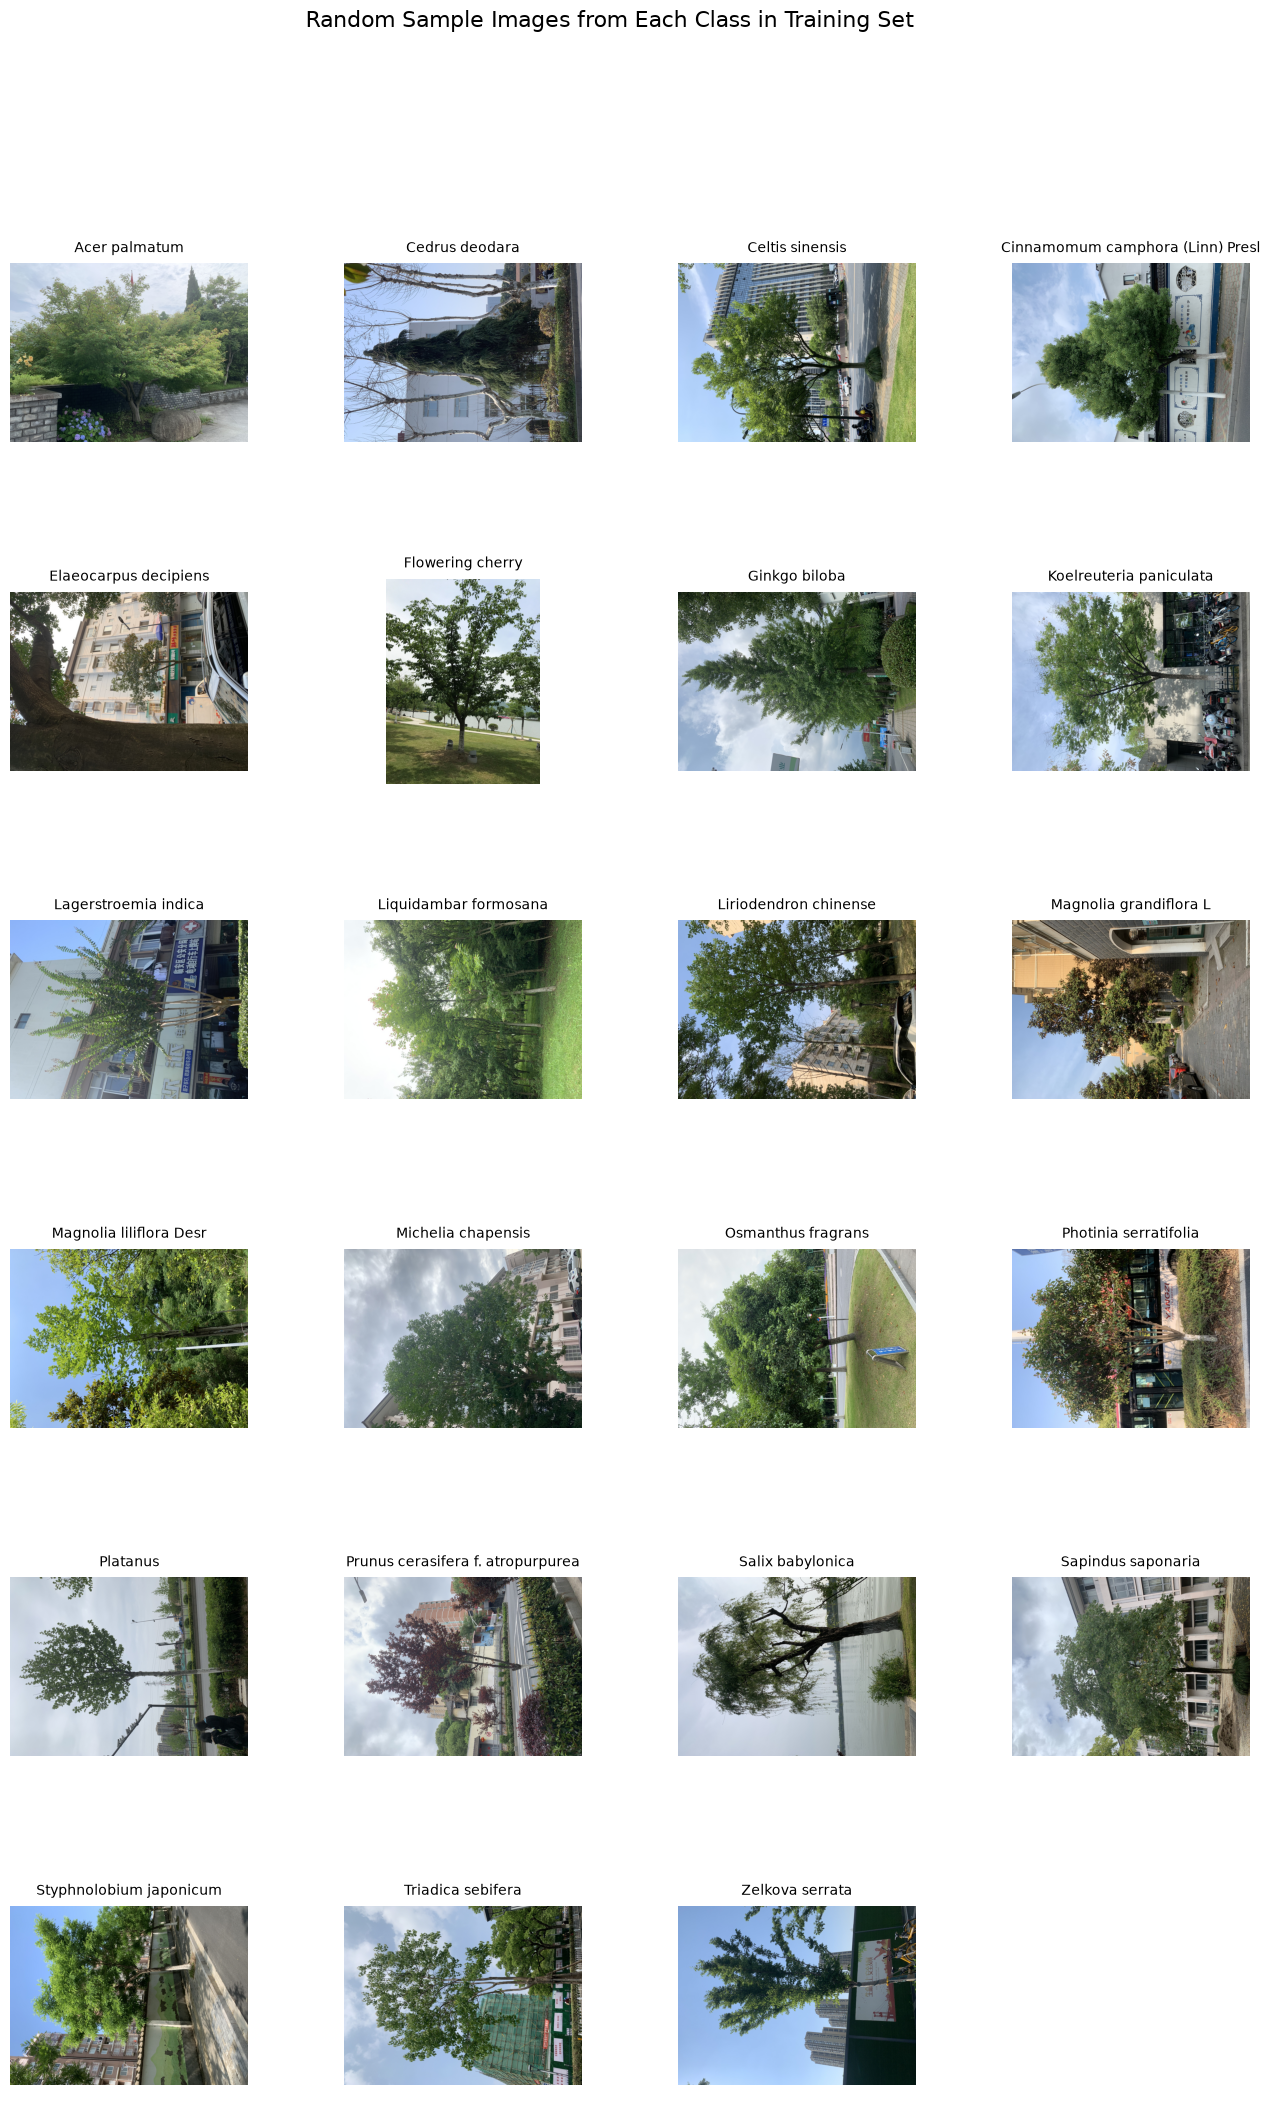

In [50]:
import math

train_path = dataset_path / "train"
classes = sorted(
    folder.name for folder in train_path.iterdir() if folder.is_dir()
)

n_cols = 4
n_rows = math.ceil(len(classes) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.asarray(axes).flatten()

for ax_index, class_name in enumerate(classes):
    class_path = train_path / class_name
    image_files = [
        file for file in class_path.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    if image_files:
        random_image_file = random.choice(image_files)
        image = Image.open(random_image_file)
        axes[ax_index].imshow(image)
        axes[ax_index].set_title(class_name, fontsize=10, pad=8)
        axes[ax_index].axis("off")

for ax_index in range(len(classes), len(axes)):
    axes[ax_index].axis("off")

fig.suptitle("Random Sample Images from Each Class in Training Set", fontsize=16)
plt.subplots_adjust(wspace=0.4, hspace=0.6)
plt.show()

Display one random class image from splits

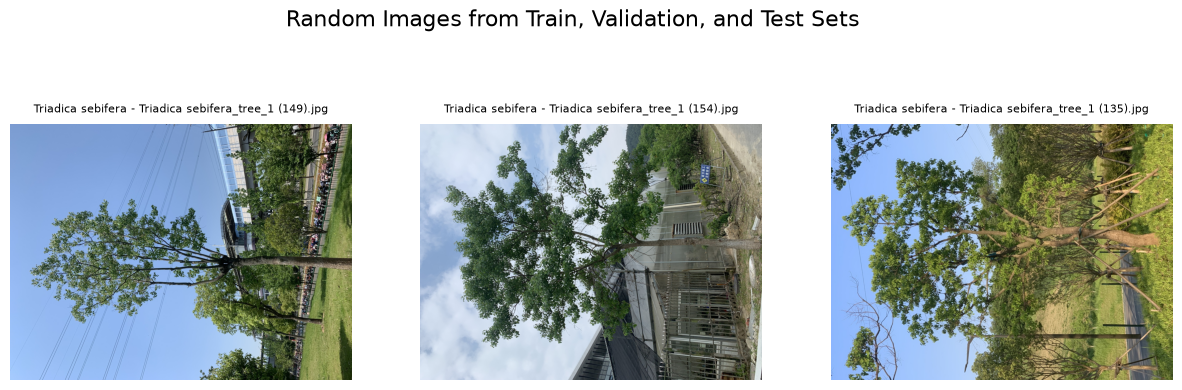

In [66]:
import random

species = random.choice(list(train_class))

train_species_path = dataset_path / "train" / species
val_species_path = dataset_path / "val" / species
test_species_path = dataset_path / "test" / species

image_extensions = [".jpg", ".jpeg", ".png", ".gif", ".bmp", ".tiff", ".webp"]

def get_random_image_from_species(folder):
    return [
        file for file in folder.rglob("*") 
        if file.is_file() and file.suffix.lower() in image_extensions
    ]    

train_species_images = get_random_image_from_species(train_species_path)
val_species_images = get_random_image_from_species(val_species_path)
test_species_images = get_random_image_from_species(test_species_path)

random_train_image = random.choice(train_species_images)
random_val_image = random.choice(val_species_images)
random_test_image = random.choice(test_species_images)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
images = [random_train_image, random_val_image, random_test_image]
for ax, img_path in zip(axes, images):
    if img_path:
        image = Image.open(img_path)
        ax.imshow(image)
        ax.set_title(f"{img_path.parent.name} - {img_path.name}", fontsize=8, pad=8)
        ax.axis('off')
plt.suptitle('Random Images from Train, Validation, and Test Sets', fontsize=16)
plt.show()

Inspect image dimentions

In [10]:
sizes = []
formats = Counter()
image_extensions = [".jpg", ".jpeg", ".png", ".gif", ".bmp", ".tiff", ".webp"]

for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in image_extensions:
        try:
            with Image.open(image_file) as img:
                sizes.append(img.size)
                formats[img.format] += 1

        except Exception as e:
            print(f"Error processing {image_file}: {e}")
print("Number of images processed:", len(sizes))
print("\nMost common image formats:")

for format, count in formats.most_common(20):
    print(f"Format: {format}, Count: {count}")

for size, count in Counter(sizes).most_common(20):
    print(f"Size: {size}, ->, Count: {count}")

Number of images processed: 4804

Most common image formats:
Format: JPEG, Count: 4804
Size: (1600, 1200), ->, Count: 4508
Size: (1200, 1600), ->, Count: 194
Size: (1199, 1600), ->, Count: 26
Size: (1283, 1600), ->, Count: 4
Size: (1065, 1600), ->, Count: 2
Size: (973, 1600), ->, Count: 2
Size: (1350, 1600), ->, Count: 2
Size: (1275, 1600), ->, Count: 2
Size: (1181, 1600), ->, Count: 2
Size: (1133, 1600), ->, Count: 2
Size: (1600, 1504), ->, Count: 1
Size: (1094, 1600), ->, Count: 1
Size: (948, 1600), ->, Count: 1
Size: (1126, 1600), ->, Count: 1
Size: (1250, 1600), ->, Count: 1
Size: (1404, 1600), ->, Count: 1
Size: (1509, 1600), ->, Count: 1
Size: (1238, 1600), ->, Count: 1
Size: (1399, 1600), ->, Count: 1
Size: (1575, 1600), ->, Count: 1


Find potentially sideways images

Portrait images: 289
Landscape images: 4515
Square images: 0


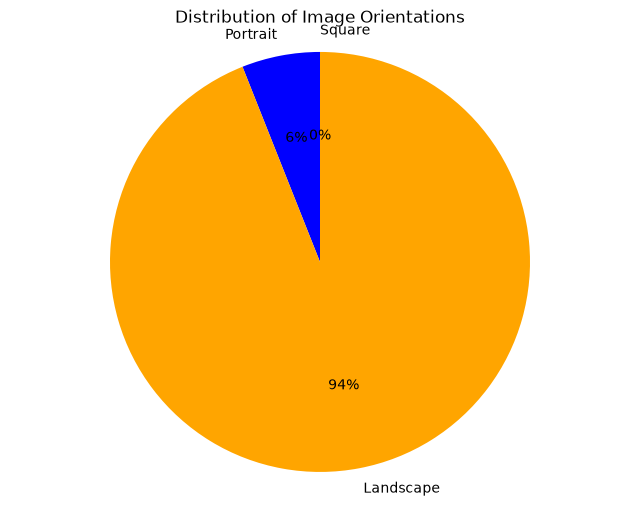

In [19]:
portrait = 0
landscape = 0
square = 0

for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in image_extensions:
        try:
            with Image.open(image_file) as img:
                width, height = img.size
                if width > height:
                    landscape += 1
                elif width < height:
                    portrait += 1
                else:
                    square += 1

        except Exception as e:
            print(f"Error processing {image_file}: {e}")

print(f"Portrait images: {portrait}")
print(f"Landscape images: {landscape}")
print(f"Square images: {square}")

plt.figure(figsize=(8, 6))
labels = ['Portrait', 'Landscape', 'Square']
sizes = [portrait, landscape, square]
plt.pie(
    sizes,
    labels=labels,
    colors=['blue', 'orange', 'green'],
    autopct='%1.0f%%',
    startangle=90
)
plt.title('Distribution of Image Orientations')
plt.axis('equal')
plt.show()

Examine aspect ratios of images in the dataset to understand their distribution. This can help in preprocessing steps, such as resizing or cropping, to ensure consistency across the dataset.

Minum width: 837
Maximum width: 1600
Minum height: 798
Maximum height: 1600
Minum aspect ratio: 0.523125
Maximum aspect ratio: 2.0050125313283207
Average width: 1576.41
Average height: 1223.84
Average aspect ratio: 1.30


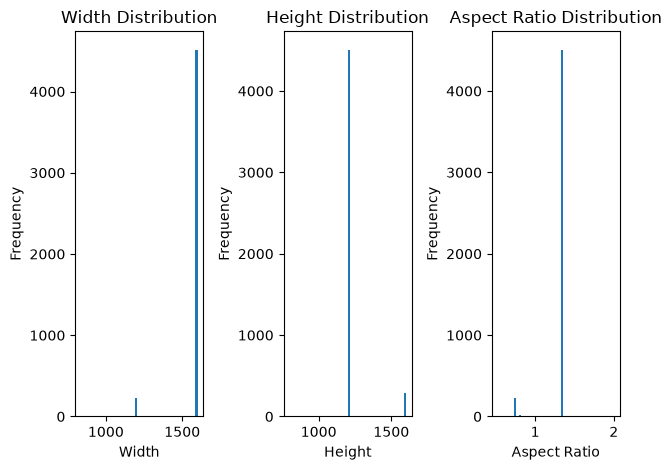

In [15]:
widths = []
heights = []
aspect_ratios = []

for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in image_extensions:
        try:
            with Image.open(image_file) as img:
                width, height = img.size
                widths.append(width)
                heights.append(height)
                aspect_ratios.append(width / height)

        except Exception as e:
            print(f"Error processing {image_file}: {e}")

print("Minum width:", min(widths))
print("Maximum width:", max(widths))
print("Minum height:", min(heights))
print("Maximum height:", max(heights))
print("Minum aspect ratio:", min(aspect_ratios))
print("Maximum aspect ratio:", max(aspect_ratios))

print(f"Average width: {sum(widths) / len(widths):.2f}")
print(f"Average height: {sum(heights) / len(heights):.2f}")
print(f"Average aspect ratio: {sum(aspect_ratios) / len(aspect_ratios):.2f}")

plt.Figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.hist(widths, bins=50)
plt.title("Width Distribution")
plt.xlabel("Width")
plt.ylabel("Frequency")

plt.subplot(1, 3, 2)
plt.hist(heights, bins=50)
plt.title("Height Distribution")
plt.xlabel("Height")
plt.ylabel("Frequency")

plt.subplot(1, 3, 3)
plt.hist(aspect_ratios, bins=50)
plt.title("Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Check image quality

In [12]:
low_resolution_images = []
for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in image_extensions:
        try:
            with Image.open(image_file) as img:
                width, height = img.size
                if width < 244 or height < 224:
                    low_resolution_images.append((image_file, (width, height)))

        except Exception as e:
            print(f"Error processing {image_file}: {e}")

print(f"Number of low-resolution images: {len(low_resolution_images)}")
for image, size in low_resolution_images:
    print(f"Image: {image}, Size: {size}")

Number of low-resolution images: 0


PIL integrity check: open every image and report unreadable/corrupt files

In [52]:
bad_images = []

for image_file in dataset_path.rglob("*"):
    if image_file.is_file() and image_file.suffix.lower() in image_extensions:
        try:
            with Image.open(image_file) as img:
                img.verify()
        except Exception as e:
            bad_images.append((str(image_file), str(e)))

print(f"Unreadable/corrupt images: {len(bad_images)}")

if bad_images:
    for path, error in bad_images[:20]:
        print(path, "->", error)
else:
    print("All image files passed the PIL integrity check.")


Unreadable/corrupt images: 0
All image files passed the PIL integrity check.


## Check for duplicate images

Exact duplicate files are detected using MD5 hashes within each split and across
train/validation/test splits.

- Duplicates within the same split are documented.
- Exact duplicates across different splits are treated as potential data leakage,
  because the same image can otherwise appear in both training and evaluation.
- This notebook **does not delete or move original files**. It reports the duplicates
  so that the dataset can be cleaned safely before final model evaluation.

Check dupliate within splits dataset

In [26]:
def md5_hash(file_path, chunk_size=1024 * 1024):
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# Store duplicate information in a dictionary
duplicate_info = {}

for split in ["train", "val", "test"]:
    split_path = dataset_path / split

    print(f"\n{'='*60}")
    print(f"\nChecking for duplicates in {split} set.")
    print(f"{'='*60}")

    hash_to_files = defaultdict(list)
    image_files =[
        file for file in split_path.rglob("*") 
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    print(f"Image files found in {split} set: {len(image_files)}")

    for image_file in image_files:
        try:
            file_hash = md5_hash(image_file)
            hash_to_files[file_hash].append(image_file)
        except Exception as e:
            print(f"Error processing {image_file}: {e}")
    duplicates = {hash: files for hash, files in hash_to_files.items() if len(files) > 1}

    if duplicates:
        for i, (file_hash, files) in enumerate(duplicates.items(), start=1):
            print(f"\nDuplicate group {i}:")
            print(f"Hash: {file_hash}")
            for file in files:
                print(f"  {file}")

    print(f"Number of duplicate groups in {split} set: {len(duplicates)}")

    if not duplicates:
        print(f"No duplicates found in {split} set.")

                    



Checking for duplicates in train set...
Image files found in train set: 3850

Duplicate group 1:
Hash: 414dfb7f67934369e3bcbccdbe4c358a
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Cedrus deodara\Cedrus deodara_tree_1 (20).jpg
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Cedrus deodara\Cedrus deodara_tree_1 (24).jpg

Duplicate group 2:
Hash: f40246bdf17fbb4d686d179f4a3c1373
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (128).jpg
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (47).jpg

Duplicate group 3:
Hash: 76624dc70de1d9b8d860cf095e1dfc50
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (131).jpg
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (80).jpg

Duplicate group 4:
Hash: d0511e017090f13ec9442834d6bf04d2
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (132).jpg
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\tr

Check duplicate between splits

In [28]:
split_pairs = [("train", "val"), ("train", "test"), ("val", "test")]
cross_split_duplicates = {}

for split1, split2 in split_pairs:
    split1_path = dataset_path / split1
    split2_path = dataset_path / split2

    print(f"\n{'='*60}")
    print(f"\nChecking for duplicates between {split1} and {split2} sets.")
    print(f"{'='*60}")

    hash_to_files_split1 = defaultdict(list)
    hash_to_files_split2 = defaultdict(list)

    image_files_split1 = [
        file for file in split1_path.rglob("*") 
        if file.is_file() and file.suffix.lower() in image_extensions
    ]
    image_files_split2 = [
        file for file in split2_path.rglob("*") 
        if file.is_file() and file.suffix.lower() in image_extensions
    ]
    
    print(f"Image files found in {split1} set: {len(image_files_split1)}")
    print(f"Image files found in {split2} set: {len(image_files_split2)}")

    for image_file in image_files_split1:
        try:
            file_hash = md5_hash(image_file)
            hash_to_files_split1[file_hash].append(image_file)
        except Exception as e:
            print(f"Error processing {image_file}: {e}")

    for image_file in image_files_split2:
        try:
            file_hash = md5_hash(image_file)
            hash_to_files_split2[file_hash].append(image_file)
        except Exception as e:
            print(f"Error processing {image_file}: {e}")

    common_hashes = set(hash_to_files_split1.keys()) & set(hash_to_files_split2.keys())

    cross_split_duplicates[(split1, split2)] = common_hashes
    print(f"Number of duplicate hashes between {split1} and {split2} sets: {len(common_hashes)}")

    if len(common_hashes) == 0:
        print(f"No duplicates found between {split1} and {split2} sets.")
    else:
        print(f"Found duplicates between {split1} and {split2} sets.")
        for i, file_hash in enumerate(common_hashes, start=1):
            print(f"\nDuplicate hash {i}: {file_hash}")
            print(f"Files in {split1} set:")
            for file in hash_to_files_split1[file_hash]:
                print(f"  {file}")
            print(f"Files in {split2} set:")
            for file in hash_to_files_split2[file_hash]:
                print(f"  {file}")


    



Checking for duplicates between train and val sets.
Image files found in train set: 3850
Image files found in val set: 482
Number of duplicate hashes between train and val sets: 10
Found duplicates between train and val sets.

Duplicate hash 1: b0046ea9abde71387f750baa7678f22a
Files in train set:
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Flowering cherry\Flowering cherry_tree_1 (69).jpg
Files in val set:
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\val\Flowering cherry\Flowering cherry_tree_1 (130).jpg

Duplicate hash 2: eba8568828ee87276180af976bda43ff
Files in train set:
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Photinia serratifolia\Photinia serratifolia_tree_1 (139).JPG
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Photinia serratifolia\Photinia serratifolia_tree_1 (68).JPG
Files in val set:
  D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\val\Photinia serratifolia\Photinia serratifolia_tree_1 (117).JPG

Duplicate hash 3: 2617df0d040c662cf548ff6df9af82d7
Files in train set:
  D:\NEUTRAL_TOMMI\GROUPPR

## Preprocessing decision

Based on the inspection above:

1. **File format:** all 4,804 images are JPEG, so no format conversion is required.
2. **Image quality:** the smallest image is 837×798 pixels, so there are no very small images according to the chosen threshold.
3. **Orientation:** both landscape and portrait images are present. Portrait orientation is not automatically treated as an error because a portrait photograph can be a valid tree image.
4. **Aspect ratio:** images have different aspect ratios, so preprocessing should avoid unnecessary geometric distortion.
5. **Duplicates:** exact duplicates within splits were found, and 10 exact duplicate hashes occur between train and validation. These should be resolved before final evaluation to avoid data leakage.
6. **Original data:** the notebook keeps the original files unchanged and performs model preprocessing dynamically through torchvision transforms.

# Preprocessing and data augmentation

We keep the original image files unchanged and apply preprocessing dynamically.
Resize(256) preserves the original aspect ratio because it resizes the shorter edge.
CenterCrop(224) then produces the model input size.
#
Training augmentation:
   - RandomHorizontalFlip: realistic left/right variation
Validation/test:
   - deterministic preprocessing only

We intentionally do NOT use vertical flipping because upside-down trees are
unrealistic. Rotation/color augmentation can be tested later if model errors
suggest it is useful.

In [54]:
from PIL import ImageOps

IMG_SIZE = 224
RESIZE_SIZE = 256

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Lambda(lambda img: ImageOps.exif_transpose(img).convert("RGB")),
    transforms.Resize(RESIZE_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_test_transform = transforms.Compose([
    transforms.Lambda(lambda img: ImageOps.exif_transpose(img).convert("RGB")),
    transforms.Resize(RESIZE_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("Training transform:")
print(train_transform)
print("\nValidation/test transform:")
print(val_test_transform)



Training transform:
Compose(
    Lambda()
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation/test transform:
Compose(
    Lambda()
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


Create the Pytorch datasets

In [55]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(root=dataset_path / "train", transform=train_transform)
val_dataset = ImageFolder(root=dataset_path / "val", transform=val_test_transform)
test_dataset = ImageFolder(root=dataset_path / "test", transform=val_test_transform)

print(f"Number of training samples: {len(train_dataset)}")
print("\nClasses:")
for i, class_name in enumerate(train_dataset.classes):
    print(f"  {i}: {class_name}")

print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")

Number of training samples: 3850

Classes:
  0: Acer palmatum
  1: Cedrus deodara
  2: Celtis sinensis
  3: Cinnamomum camphora (Linn) Presl
  4: Elaeocarpus decipiens
  5: Flowering cherry
  6: Ginkgo biloba
  7: Koelreuteria paniculata
  8: Lagerstroemia indica
  9: Liquidambar formosana
  10: Liriodendron chinense
  11: Magnolia grandiflora L
  12: Magnolia liliflora Desr
  13: Michelia chapensis
  14: Osmanthus fragrans
  15: Photinia serratifolia
  16: Platanus
  17: Prunus cerasifera f. atropurpurea
  18: Salix babylonica
  19: Sapindus saponaria
  20: Styphnolobium japonicum
  21: Triadica sebifera
  22: Zelkova serrata
Number of validation samples: 482
Number of test samples: 472


Verify class mapping

In [56]:
print("Train classes:")
print(train_dataset.class_to_idx)

print("Validation classes:")
print(val_dataset.class_to_idx)

print("Test classes:")
print(test_dataset.class_to_idx)

Train classes:
{'Acer palmatum': 0, 'Cedrus deodara': 1, 'Celtis sinensis': 2, 'Cinnamomum camphora (Linn) Presl': 3, 'Elaeocarpus decipiens': 4, 'Flowering cherry': 5, 'Ginkgo biloba': 6, 'Koelreuteria paniculata': 7, 'Lagerstroemia indica': 8, 'Liquidambar formosana': 9, 'Liriodendron chinense': 10, 'Magnolia grandiflora L': 11, 'Magnolia liliflora Desr': 12, 'Michelia chapensis': 13, 'Osmanthus fragrans': 14, 'Photinia serratifolia': 15, 'Platanus': 16, 'Prunus cerasifera f. atropurpurea': 17, 'Salix babylonica': 18, 'Sapindus saponaria': 19, 'Styphnolobium japonicum': 20, 'Triadica sebifera': 21, 'Zelkova serrata': 22}
Validation classes:
{'Acer palmatum': 0, 'Cedrus deodara': 1, 'Celtis sinensis': 2, 'Cinnamomum camphora (Linn) Presl': 3, 'Elaeocarpus decipiens': 4, 'Flowering cherry': 5, 'Ginkgo biloba': 6, 'Koelreuteria paniculata': 7, 'Lagerstroemia indica': 8, 'Liquidambar formosana': 9, 'Liriodendron chinense': 10, 'Magnolia grandiflora L': 11, 'Magnolia liliflora Desr': 12, 

Identify largest class, smallest class and ratio between largest and smallest in train dataset

In [57]:
train_counts = Counter(
    train_dataset.classes[label] for label in train_dataset.targets
)

largest_class_name = max(train_counts, key=train_counts.get)
smallest_class_name = min(train_counts, key=train_counts.get)

largest_count = train_counts[largest_class_name]
smallest_count = train_counts[smallest_class_name]
imbalance_ratio = largest_count / smallest_count

print(f"Largest class: {largest_class_name} with {largest_count} samples")
print(f"Smallest class: {smallest_class_name} with {smallest_count} samples")
print(f"Imbalance ratio: {imbalance_ratio:.2f}")



Largest class: Cinnamomum camphora (Linn) Presl with 234 samples
Smallest class: Lagerstroemia indica with 65 samples
Imbalance ratio: 3.60


Create DataLoaders

In [58]:
from torch.utils.data import Dataset, DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Check datatype and shape of train dataset 

In [59]:

images, labels = next(iter(train_loader))
print(f"Batch of images shape: {images.shape}")
print(f"Batch of labels shape: {labels.shape}")
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Tensor minimum:", images.min().item())
print("Tensor maximum:", images.max().item())
print("Tensor mean:", images.mean().item())
print("Tensor standard deviation:", images.std().item())

Batch of images shape: torch.Size([32, 3, 224, 224])
Batch of labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Tensor minimum: -2.1179039478302
Tensor maximum: 2.640000104904175
Tensor mean: -0.17610181868076324
Tensor standard deviation: 1.1265769004821777


Visual verification of augmentation on one original image

The same image is transformed several times. This checks that the augmentation remains realistic and does not remove important tree features.

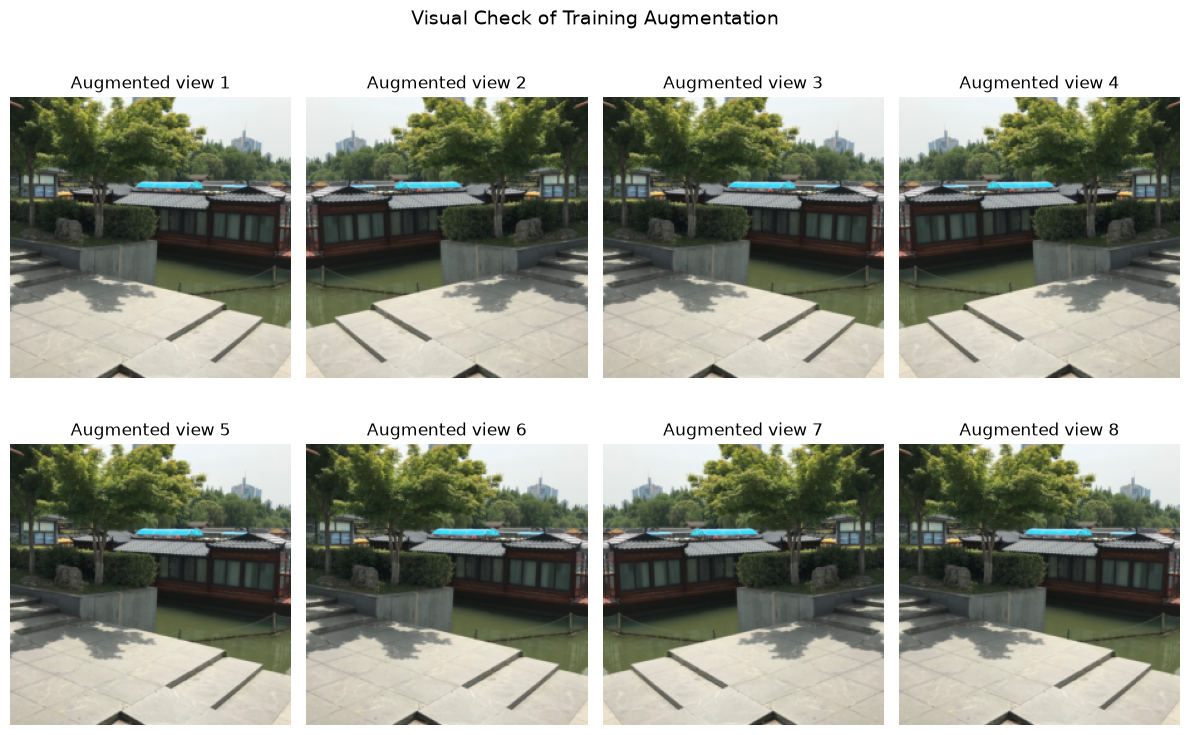

Original image: D:\NEUTRAL_TOMMI\GROUPPROJECT\tree\train\Acer palmatum\Acer palmatum_tree_1 (1).jpg
Check that the tree remains realistic and that important visual features are not systematically cropped.


In [60]:
from PIL import Image

sample_image_path = train_dataset.samples[0][0]
original_image = Image.open(sample_image_path).convert("RGB")

augmentation_only = transforms.Compose([
    transforms.Resize(RESIZE_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5)
])

plt.figure(figsize=(12, 8))

for i in range(8):
    augmented = augmentation_only(original_image)
    plt.subplot(2, 4, i + 1)
    plt.imshow(augmented)
    plt.title(f"Augmented view {i+1}")
    plt.axis("off")

plt.suptitle("Visual Check of Training Augmentation", fontsize=14)
plt.tight_layout()
plt.show()

print("Original image:", sample_image_path)
print("Check that the tree remains realistic and that important visual features are not systematically cropped.")

Visualize the transformed images


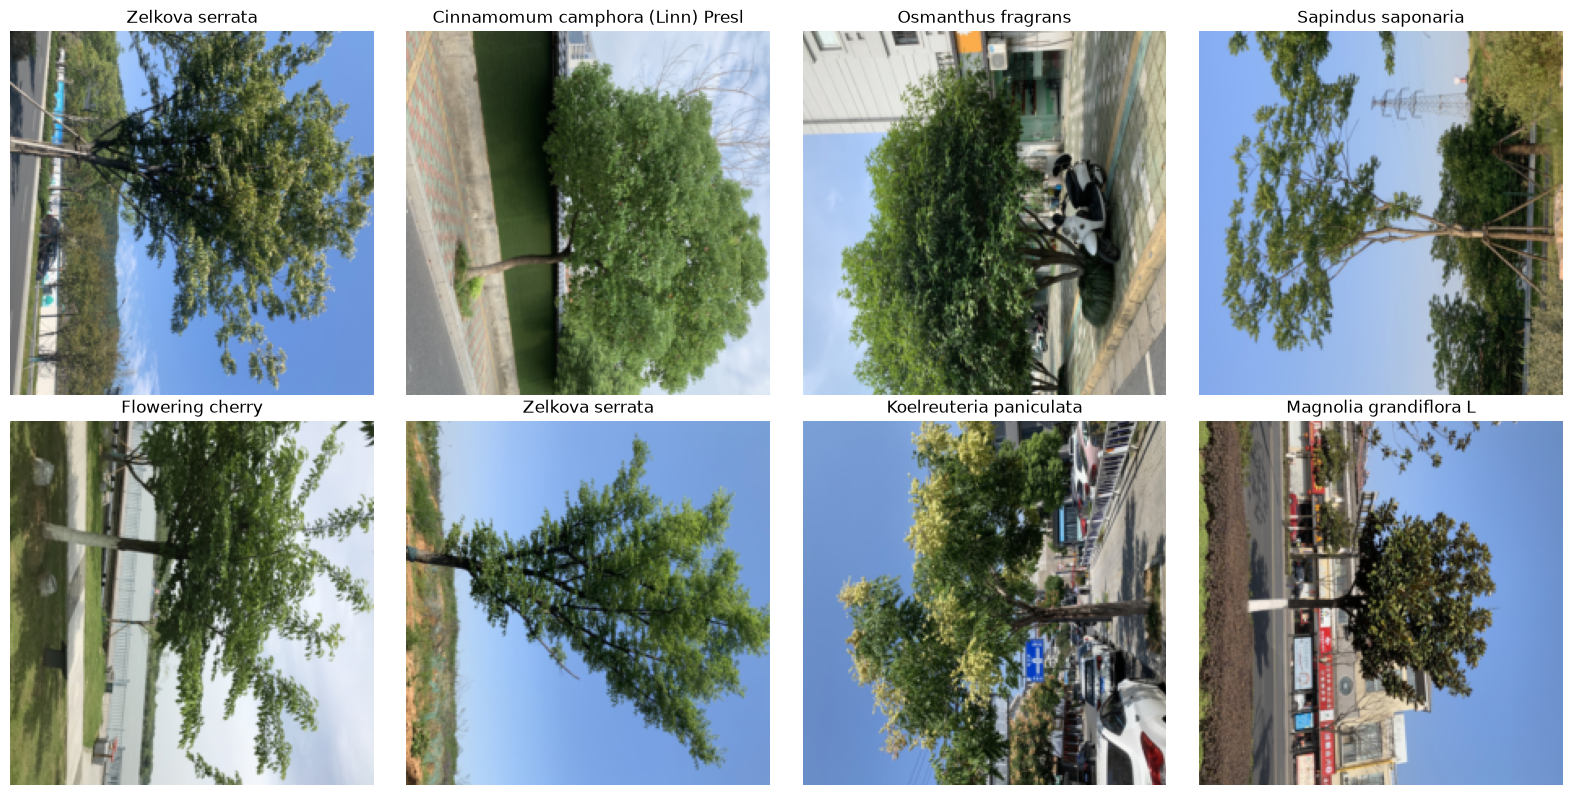

In [45]:
def visualize_batch(images, labels, class_names, n=8):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    plt.figure(figsize=(16, 8))
    for i in range(min(n, len(images))):
        img = images[i].numpy().transpose((1, 2, 0))
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.subplot(2, n // 2, i + 1)
        plt.imshow(img)
        plt.title(class_names[labels[i]])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

visualize_batch(images, labels, train_dataset.classes, n=8)
